In [36]:
!pip install -q pyyaml

from google.colab import files
import os, zipfile

# Upload semua zip dataset (bisa pilih banyak file sekaligus)
uploaded = files.upload()

os.makedirs("datasets", exist_ok=True)
for fname in uploaded:
    folder = os.path.join("datasets", os.path.splitext(fname)[0])
    with zipfile.ZipFile(fname) as z:
        z.extractall(folder)
    print("Diekstrak:", folder)

Saving Sortir Limbah Elektronik.v5i.yolov11.zip to Sortir Limbah Elektronik.v5i.yolov11.zip
Saving Biomedical waste segregation.v1i.yolov11.zip to Biomedical waste segregation.v1i.yolov11.zip
Diekstrak: datasets/Sortir Limbah Elektronik.v5i.yolov11
Diekstrak: datasets/Biomedical waste segregation.v1i.yolov11


In [45]:
# Kelas final (urutan = class id)
FINAL = ["anorganik", "b3", "kertas", "organik", "residu"]

DATASETS = [
    # {
    #     "path": "datasets/Sampah-Indonesia.v2i.yolov11",
    #     "map": {"anorganik": "anorganik", "b3": "b3", "organik": "organik"},
    #     "max_images": None,           # None = pakai semua
    # },
    {
        "path": "datasets/Sampah.v1i.yolov11",
        "map": {
            "Sampah Anorganik": "anorganik",
            "Sampah B3": "b3",
            "Sampah Kertas": "kertas",
            "Sampah Organik": "organik",
            "Sampah Residu": "residu",
        },
        "max_images": None,
    },
    {
        "path": "datasets/e-waste.v2i.yolov11",
        "map": {
            "Battery": "b3",
            "Mobile": "b3",
            "PCB": "b3",
            "Mouse": "b3",
            "Keyboard": "b3",
            "Player": "b3",
        },
        "max_images": None,
        "only_pure": True,
    },
    {
        "path": "datasets/Waste Augmentation Residual.v1i.yolov11",
        "map": {"residual": "residu"},
        "max_images": None,
        "only_pure": True,
    },
        # Paper: kertas saja
    {
        "path": "datasets/Paper.v1i.yolov11",
        "map": {"Recyclable paper": "kertas"},
        "max_images": None,
        "only_pure": True,
    },
    # Paper: anorganik saja (kelas yang tadinya dibuang)
    {
        "path": "datasets/Paper.v1i.yolov11",
        "map": {
            "Recyclable plastic": "anorganik",
            "Recyclable metal": "anorganik",
            "Recyclable glass": "anorganik",
        },
        "max_images": 200,
        "only_pure": True,
    },
    # 12 kelas: anorganik + kertas
    {
        "path": "datasets/sampah organik anorganik.v2-12-kelas.yolov11",
        "map": {
            "botol": "anorganik",
            "gelas plastik": "anorganik",
            "kaleng": "anorganik",
            "kantong plastik": "anorganik",
            "kardus": "kertas",
            "kertas": "kertas",
        },
        "max_images": 250,
        "only_pure": True,
    },
    # 12 kelas: organik saja
    {
        "path": "datasets/sampah organik anorganik.v2-12-kelas.yolov11",
        "map": {
            "apel": "organik",
            "daun": "organik",
            "jagung": "organik",
            "sisa nasi": "organik",
            "tulang ayam": "organik",
            "wortel": "organik",
        },
        "max_images": 250,
        "only_pure": True,
    },
    {
        "path": "datasets/battery.v1i.yolov11",   # salin dari output cell 2
        "map": {"battery": "b3"},
        "max_images": 150,
    },
    {
        "path": "datasets/kategori sampah.v1i.yolov11",   # sesuaikan dengan output cell 2
        "map": {
            "kaca": "anorganik",
            "logam": "anorganik",
            "plastik": "anorganik",
            "kertas": "kertas",
        },
        "max_images": 1000,
        "only_pure": True,       # skip gambar yang berisi 'tumpukan'
    },
    # Sampah (adam-zutyf): organik dan anorganik
    {
        "path": "datasets/sampah.v6i.yolov11",            # sesuaikan dengan output cell 2
        "map": {"anorganik": "anorganik", "organik": "organik"},
        "max_images": None,
    },
    # Sortir Limbah Elektronik (Indonesia): 'Lainnya' dibuang
    {
        "path": "datasets/Sortir Limbah Elektronik.v5i.yolov11",   # sesuaikan dengan output cell 2
        "map": {"Baterai": "b3", "PCB": "b3", "Speaker": "b3", "Dinamo": "b3"},
        "max_images": 750,
        "only_pure": True,
    },
    # Biomedical waste: kelas 'red' -> b3 (cek visual dulu, lihat catatan)
    {
        "path": "datasets/Biomedical waste segregation.v1i.yolov11",   # sesuaikan dengan output cell 2
        "map": {"red": "b3"},
        "max_images": 120,
    },
]

OUT = "merged"
SEED = 42

In [22]:
from pathlib import Path

for d in sorted(Path("datasets").iterdir()):
    has_yaml = (d / "data.yaml").exists()
    print(("OK   " if has_yaml else "KOSONG/BERSARANG ") + str(d))
    if not has_yaml:
        # cek apakah data.yaml ada satu tingkat di dalam (zip yang punya folder pembungkus)
        for sub in d.iterdir():
            if sub.is_dir() and (sub / "data.yaml").exists():
                print("      -> data.yaml ada di:", sub)

OK   datasets/Paper.v1i.yolov11
OK   datasets/Sampah.v1i.yolov11
OK   datasets/Waste Augmentation Residual.v1i.yolov11
OK   datasets/battery.v1i.yolov11
OK   datasets/e-waste.v2i.yolov11
OK   datasets/kategori sampah.v1i.yolov11
OK   datasets/sampah organik anorganik.v2-12-kelas.yolov11
OK   datasets/sampah.v6i.yolov11


In [46]:
import shutil, random, yaml
from pathlib import Path
from collections import Counter

SPLITS = ["train", "valid", "test"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
random.seed(SEED)

def to_box(vals):
    """4 angka = bounding box; lebih dari itu = polygon -> diubah jadi box."""
    if len(vals) == 4:
        return vals
    xs, ys = vals[0::2], vals[1::2]
    x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
    return [(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1]

def read_names(root):
    names = yaml.safe_load(open(root / "data.yaml"))["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return names

if Path(OUT).exists():
    shutil.rmtree(OUT)

stats = {s: Counter() for s in SPLITS}
n_images = Counter()

for ds_i, ds in enumerate(DATASETS):
    root = Path(ds["path"])
    names = read_names(root)
    only_pure = ds.get("only_pure", False)

    unmapped = [n for n in names if n not in ds["map"]]
    if unmapped:
        print(f"[{root.name}] kelas dibuang: {unmapped}")
    wrong = [k for k in ds["map"] if k not in names]
    if wrong:
        print(f"[{root.name}] PERINGATAN: kunci map tidak ada di data.yaml: {wrong}")
        print(f"   nama asli di dataset: {names}")

    # 1) Kumpulkan kandidat per split (sudah difilter)
    cands = {}
    for split in SPLITS:
        img_dir, lbl_dir = root / split / "images", root / split / "labels"
        if not img_dir.exists():
            continue

        items = []
        for img in sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXT):
            lbl = lbl_dir / (img.stem + ".txt")
            new_lines, local, dropped = [], Counter(), 0
            if lbl.exists():
                for line in lbl.read_text().splitlines():
                    p = line.split()
                    if not p:
                        continue
                    old = names[int(p[0])]
                    if old not in ds["map"]:
                        dropped += 1
                        continue
                    final = ds["map"][old]
                    box = to_box([float(v) for v in p[1:]])
                    new_lines.append(f"{FINAL.index(final)} " + " ".join(f"{v:.6f}" for v in box))
                    local[final] += 1

            if not new_lines:                 # tidak ada objek yang dipakai
                continue
            if only_pure and dropped:         # ada objek kelas lain -> skip
                continue
            items.append((img, new_lines, local))
        cands[split] = items

    # 2) Batasi jumlah gambar (proporsional per split, dihitung dari kandidat valid)
    total = sum(len(v) for v in cands.values())
    print(f"[{root.name}] kandidat valid: {total} gambar", end="")
    print(f" -> diambil maks {ds['max_images']}" if ds["max_images"] else " -> diambil semua")

    for split, items in cands.items():
        if ds["max_images"] and total > ds["max_images"]:
            quota = max(1, round(ds["max_images"] * len(items) / total))
            items = random.sample(items, min(quota, len(items)))

        (Path(OUT) / split / "images").mkdir(parents=True, exist_ok=True)
        (Path(OUT) / split / "labels").mkdir(parents=True, exist_ok=True)

        # 3) Salin gambar dan tulis label
        for img, new_lines, local in items:
            new_name = f"d{ds_i}_{img.name}"
            shutil.copy(img, Path(OUT) / split / "images" / new_name)
            (Path(OUT) / split / "labels" / f"{Path(new_name).stem}.txt").write_text("\n".join(new_lines))
            stats[split].update(local)
            n_images[split] += 1

Path(OUT, "data.yaml").write_text(
    f"path: {Path(OUT).resolve()}\n"
    "train: train/images\nval: valid/images\ntest: test/images\n"
    f"nc: {len(FINAL)}\nnames: {FINAL}\n"
)

print("\n=== Ringkasan ===")
for s in SPLITS:
    print(f"{s:6s}: {n_images[s]:4d} gambar | " + ", ".join(f"{k}={stats[s][k]}" for k in FINAL))

[Sampah.v1i.yolov11] kandidat valid: 249 gambar -> diambil semua
[e-waste.v2i.yolov11] kelas dibuang: ['Microwave', 'Printer', 'Television', 'Washing Machine']
[e-waste.v2i.yolov11] kandidat valid: 385 gambar -> diambil semua
[Waste Augmentation Residual.v1i.yolov11] kelas dibuang: ['recycable']
[Waste Augmentation Residual.v1i.yolov11] kandidat valid: 1072 gambar -> diambil semua
[Paper.v1i.yolov11] kelas dibuang: ['Recyclable glass', 'Recyclable metal', 'Recyclable plastic']
[Paper.v1i.yolov11] kandidat valid: 761 gambar -> diambil semua
[Paper.v1i.yolov11] kelas dibuang: ['Recyclable paper']
[Paper.v1i.yolov11] kandidat valid: 3 gambar -> diambil maks 200
[sampah organik anorganik.v2-12-kelas.yolov11] kelas dibuang: ['apel', 'daun', 'jagung', 'sisa nasi', 'tulang ayam', 'wortel']
[sampah organik anorganik.v2-12-kelas.yolov11] kandidat valid: 586 gambar -> diambil maks 250
[sampah organik anorganik.v2-12-kelas.yolov11] kelas dibuang: ['botol', 'gelas plastik', 'kaleng', 'kantong plas

In [47]:
from google.colab import files
import zipfile, shutil, random
from pathlib import Path

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
N_TEST, N_VALID, N_TRAIN_MAX = 30, 20, 110

# 1) Upload dan ekstrak zip negatif
up = files.upload()   # pilih negatif.zip
RAW = Path("negatif_raw")
if RAW.exists():
    shutil.rmtree(RAW)
RAW.mkdir()
for fname in up:
    if fname.lower().endswith(".zip"):
        with zipfile.ZipFile(fname) as z:
            z.extractall(RAW)
    else:  # kalau yang diupload gambar langsung
        shutil.copy(fname, RAW / fname)

# 2) Kumpulkan semua gambar (termasuk di subfolder), lalu acak
negs = sorted(p for p in RAW.rglob("*") if p.suffix.lower() in IMG_EXT)
random.seed(SEED)
random.shuffle(negs)
print(f"Total gambar negatif ditemukan: {len(negs)}")

# 3) Bagi: test (terpisah) -> valid -> train
neg_test  = negs[:N_TEST]
neg_valid = negs[N_TEST:N_TEST + N_VALID]
neg_train = negs[N_TEST + N_VALID:N_TEST + N_VALID + N_TRAIN_MAX]

def add_to_merged(items, split):
    (Path(OUT) / split / "images").mkdir(parents=True, exist_ok=True)
    (Path(OUT) / split / "labels").mkdir(parents=True, exist_ok=True)
    for i, p in enumerate(items):
        name = f"neg_{i:04d}{p.suffix.lower()}"
        shutil.copy(p, Path(OUT) / split / "images" / name)
        (Path(OUT) / split / "labels" / f"neg_{i:04d}.txt").write_text("")  # label kosong = background

add_to_merged(neg_train, "train")
add_to_merged(neg_valid, "valid")

# 4) Simpan negatif uji di luar merged (jangan dipakai training)
NEG_TEST_DIR = Path("negatif_test")
if NEG_TEST_DIR.exists():
    shutil.rmtree(NEG_TEST_DIR)
NEG_TEST_DIR.mkdir()
for i, p in enumerate(neg_test):
    shutil.copy(p, NEG_TEST_DIR / f"negtest_{i:04d}{p.suffix.lower()}")

print(f"train: +{len(neg_train)} | valid: +{len(neg_valid)} | negatif_test: {len(neg_test)} (di luar merged)")
if len(negs) < N_TEST + N_VALID + 60:
    print("PERINGATAN: gambar negatif masih sedikit, idealnya kumpulkan sekitar 160 gambar.")

Saving negatif.zip to negatif.zip
Total gambar negatif ditemukan: 179
train: +110 | valid: +20 | negatif_test: 30 (di luar merged)


In [48]:
import random, shutil
from collections import defaultdict, Counter
from pathlib import Path

random.seed(SEED)
RATIO = (0.70, 0.15, 0.15)   # train, valid, test
NEW = "merged_v2"

# 1) Kumpulkan semua gambar non-negatif dari ketiga split lama
items = []
for s in SPLITS:
    for img in Path(OUT, s, "images").iterdir():
        if img.name.startswith("neg_"):
            continue
        items.append((img, Path(OUT, s, "labels", img.stem + ".txt")))
print("Total gambar non-negatif:", len(items))

# 2) Kelompokkan salinan augmentasi (nama sebelum ".rf.") jadi satu grup
groups = defaultdict(list)
for img, lbl in items:
    groups[img.name.split(".rf.")[0]].append((img, lbl))

def strat_key(members):
    img, lbl = members[0]
    src = img.name.split("_")[0]                  # d0, d1, ...
    cls = Counter(int(l.split()[0]) for l in lbl.read_text().splitlines() if l.strip())
    return (src, cls.most_common(1)[0][0] if cls else -1)

buckets = defaultdict(list)
for members in groups.values():
    buckets[strat_key(members)].append(members)

# 3) Bagi per bucket (sumber, kelas dominan)
new = {s: [] for s in SPLITS}
for key, grp in buckets.items():
    random.shuffle(grp)
    n = len(grp)
    n_test = max(1, round(n * RATIO[2])) if n >= 3 else 0
    n_val  = max(1, round(n * RATIO[1])) if n >= 3 else 0
    new["test"]  += grp[:n_test]
    new["valid"] += grp[n_test:n_test + n_val]
    new["train"] += grp[n_test + n_val:]

# 4) Tulis ke folder baru
if Path(NEW).exists():
    shutil.rmtree(NEW)
for s in SPLITS:
    Path(NEW, s, "images").mkdir(parents=True)
    Path(NEW, s, "labels").mkdir(parents=True)

def copy_pair(img, lbl, split):
    shutil.copy(img, Path(NEW, split, "images", img.name))
    if lbl.exists():
        shutil.copy(lbl, Path(NEW, split, "labels", lbl.name))

for s in SPLITS:
    for members in new[s]:
        for img, lbl in members:
            copy_pair(img, lbl, s)

# negatif tetap di split semula (negatif uji sudah terpisah di negatif_test)
for s in ["train", "valid"]:
    for img in Path(OUT, s, "images").glob("neg_*"):
        copy_pair(img, Path(OUT, s, "labels", img.stem + ".txt"), s)

Path(NEW, "data.yaml").write_text(
    f"path: {Path(NEW).resolve()}\ntrain: train/images\nval: valid/images\ntest: test/images\n"
    f"nc: {len(FINAL)}\nnames: {FINAL}\n"
)

# 5) Ringkasan
for s in SPLITS:
    c = Counter()
    n = len(list(Path(NEW, s, "images").glob("*")))
    for l in Path(NEW, s, "labels").glob("*.txt"):
        for line in l.read_text().splitlines():
            if line.strip():
                c[FINAL[int(line.split()[0])]] += 1
    print(f"{s:5s}: {n:4d} gambar | " + ", ".join(f"{k}={c[k]}" for k in FINAL))

Total gambar non-negatif: 5180
train: 3738 gambar | anorganik=1622, b3=1384, kertas=1487, organik=1263, residu=1033
valid:  799 gambar | anorganik=401, b3=304, kertas=332, organik=243, residu=220
test :  773 gambar | anorganik=336, b3=284, kertas=316, organik=256, residu=219


In [49]:
from collections import defaultdict, Counter

OUT = "merged_v2"   # dipakai juga untuk training berikutnya

SRC = {f"d{i}": Path(d["path"]).name for i, d in enumerate(DATASETS)}
SRC["neg"] = "negatif"

# 1) Sumber per kelas di tiap split
inst = {s: defaultdict(Counter) for s in SPLITS}
imgs = {s: defaultdict(Counter) for s in SPLITS}
for s in SPLITS:
    for lbl in Path(OUT, s, "labels").glob("*.txt"):
        src = SRC.get(lbl.stem.split("_")[0], "?")
        cls = [FINAL[int(l.split()[0])] for l in lbl.read_text().splitlines() if l.strip()]
        for c in cls:
            inst[s][src][c] += 1
        for c in set(cls):
            imgs[s][src][c] += 1

for c in FINAL:
    print(f"\n== {c}")
    for s in SPLITS:
        parts = [f"{src}: {imgs[s][src][c]} gbr/{inst[s][src][c]} obj"
                 for src in imgs[s] if imgs[s][src][c]]
        print(f"  {s:5s} -> " + " | ".join(parts))

# 2) Perkiraan foto asli per dataset
total, uniq = defaultdict(int), defaultdict(set)
for s in SPLITS:
    for img in Path(OUT, s, "images").iterdir():
        if img.name.startswith("neg_"):
            continue
        src = SRC.get(img.name.split("_")[0], "?")
        total[src] += 1
        uniq[src].add(img.name.split(".rf.")[0])

print("\nDataset | total | foto asli (perkiraan)")
for src in total:
    print(f"{src:45s} {total[src]:4d} | {len(uniq[src])}")


== anorganik
  train -> sampah.v6i.yolov11: 69 gbr/108 obj | sampah organik anorganik.v2-12-kelas.yolov11: 115 gbr/165 obj | kategori sampah.v1i.yolov11: 533 gbr/1307 obj | Sampah.v1i.yolov11: 34 gbr/40 obj | Paper.v1i.yolov11: 1 gbr/2 obj
  valid -> Paper.v1i.yolov11: 1 gbr/7 obj | kategori sampah.v1i.yolov11: 118 gbr/323 obj | Sampah.v1i.yolov11: 7 gbr/9 obj | sampah organik anorganik.v2-12-kelas.yolov11: 24 gbr/35 obj | sampah.v6i.yolov11: 15 gbr/27 obj
  test  -> Paper.v1i.yolov11: 1 gbr/1 obj | sampah organik anorganik.v2-12-kelas.yolov11: 25 gbr/31 obj | sampah.v6i.yolov11: 16 gbr/26 obj | kategori sampah.v1i.yolov11: 113 gbr/269 obj | Sampah.v1i.yolov11: 9 gbr/9 obj

== b3
  train -> Sortir Limbah Elektronik.v5i.yolov11: 526 gbr/697 obj | battery.v1i.yolov11: 106 gbr/282 obj | Sampah.v1i.yolov11: 35 gbr/35 obj | e-waste.v2i.yolov11: 269 gbr/276 obj | Biomedical waste segregation.v1i.yolov11: 85 gbr/94 obj
  valid -> Biomedical waste segregation.v1i.yolov11: 17 gbr/24 obj | Sort

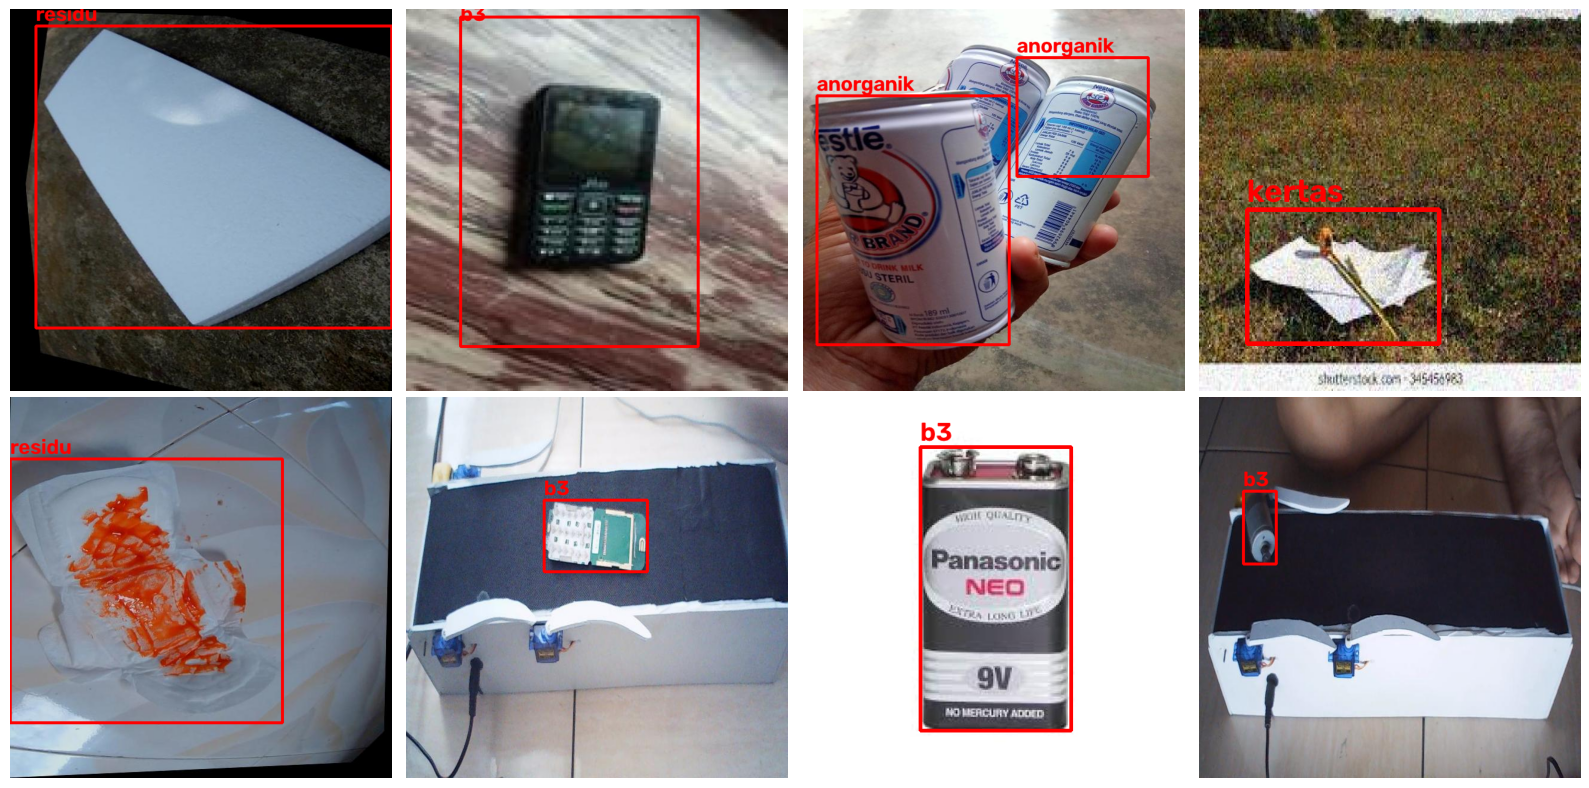

In [50]:
import cv2, matplotlib.pyplot as plt

def show_samples(split="train", n=8):
    imgs = random.sample(list(Path(OUT, split, "images").iterdir()), n)
    fig, axes = plt.subplots(2, n // 2, figsize=(4 * n // 2, 8))
    for ax, p in zip(axes.flat, imgs):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = im.shape[:2]
        for line in open(Path(OUT, split, "labels", p.stem + ".txt")):
            c, x, y, bw, bh = line.split()
            c = int(c); x, y, bw, bh = [float(v) for v in (x, y, bw, bh)]
            x1, y1 = int((x - bw / 2) * w), int((y - bh / 2) * h)
            x2, y2 = int((x + bw / 2) * w), int((y + bh / 2) * h)
            cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), 3)
            cv2.putText(im, FINAL[c], (x1, max(y1 - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 0, 0), 3)
        ax.imshow(im); ax.axis("off")
    plt.tight_layout(); plt.show()

show_samples("train")

In [51]:
!zip -qr merged.zip merged
files.download("merged.zip")



zip error: Interrupted (aborting)


FileNotFoundError: Cannot find file: merged.zip

In [52]:
!zip -qr merged_v2.zip merged_v2 negatif_test
files.download("merged_v2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Training


In [53]:
!pip install -q ultralytics onnx onnxruntime onnxslim

import torch, ultralytics
ultralytics.checks()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (ganti runtime ke GPU)")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 44.7/235.7 GB disk)
GPU: Tesla T4


In [54]:
from ultralytics import YOLO
from pathlib import Path

OUT = "merged_v2"    # pakai data hasil pembagian ulang
DATA = str(Path(OUT, "data.yaml").resolve())
IMGSZ = 416          # samakan dengan ukuran input yang akan dipakai di browser
EPOCHS = 100
BATCH = 16
PROJECT, RUN = "runs", "sampah_yolo11n_v2"   # nama baru supaya hasil v1 tidak tertimpa

for s in ["train", "valid", "test"]:
    n_img = len(list(Path(OUT, s, "images").glob("*")))
    print(f"{s:6s}: {n_img} gambar")
print(Path(DATA).read_text())

train : 3738 gambar
valid : 799 gambar
test  : 773 gambar
path: /content/merged_v2
train: train/images
val: valid/images
test: test/images
nc: 5
names: ['anorganik', 'b3', 'kertas', 'organik', 'residu']



In [55]:
model = YOLO("yolo11n.pt")   # pretrained nano, cocok untuk browser

results = model.train(
    data=DATA,
    imgsz=IMGSZ,
    epochs=EPOCHS,
    batch=BATCH,
    patience=20,          # berhenti dini jika tidak membaik
    seed=SEED,
    project=PROJECT,
    name=RUN,
    exist_ok=True,
    cos_lr=True,
    close_mosaic=10,
    plots=True,
)
BEST = Path(results.save_dir) / "weights" / "best.pt"   # path otomatis yang benar
print("Model terbaik:", BEST, BEST.exists())

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/merged_v2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=sampah_yolo11n_v2, nbs=64, nms=None, opset=None, optimize=Fals

In [56]:
BEST = Path(results.save_dir) / "weights" / "best.pt"
print(BEST, "| ada:", BEST.exists())

/content/runs/detect/runs/sampah_yolo11n_v2/weights/best.pt | ada: True


== results.png


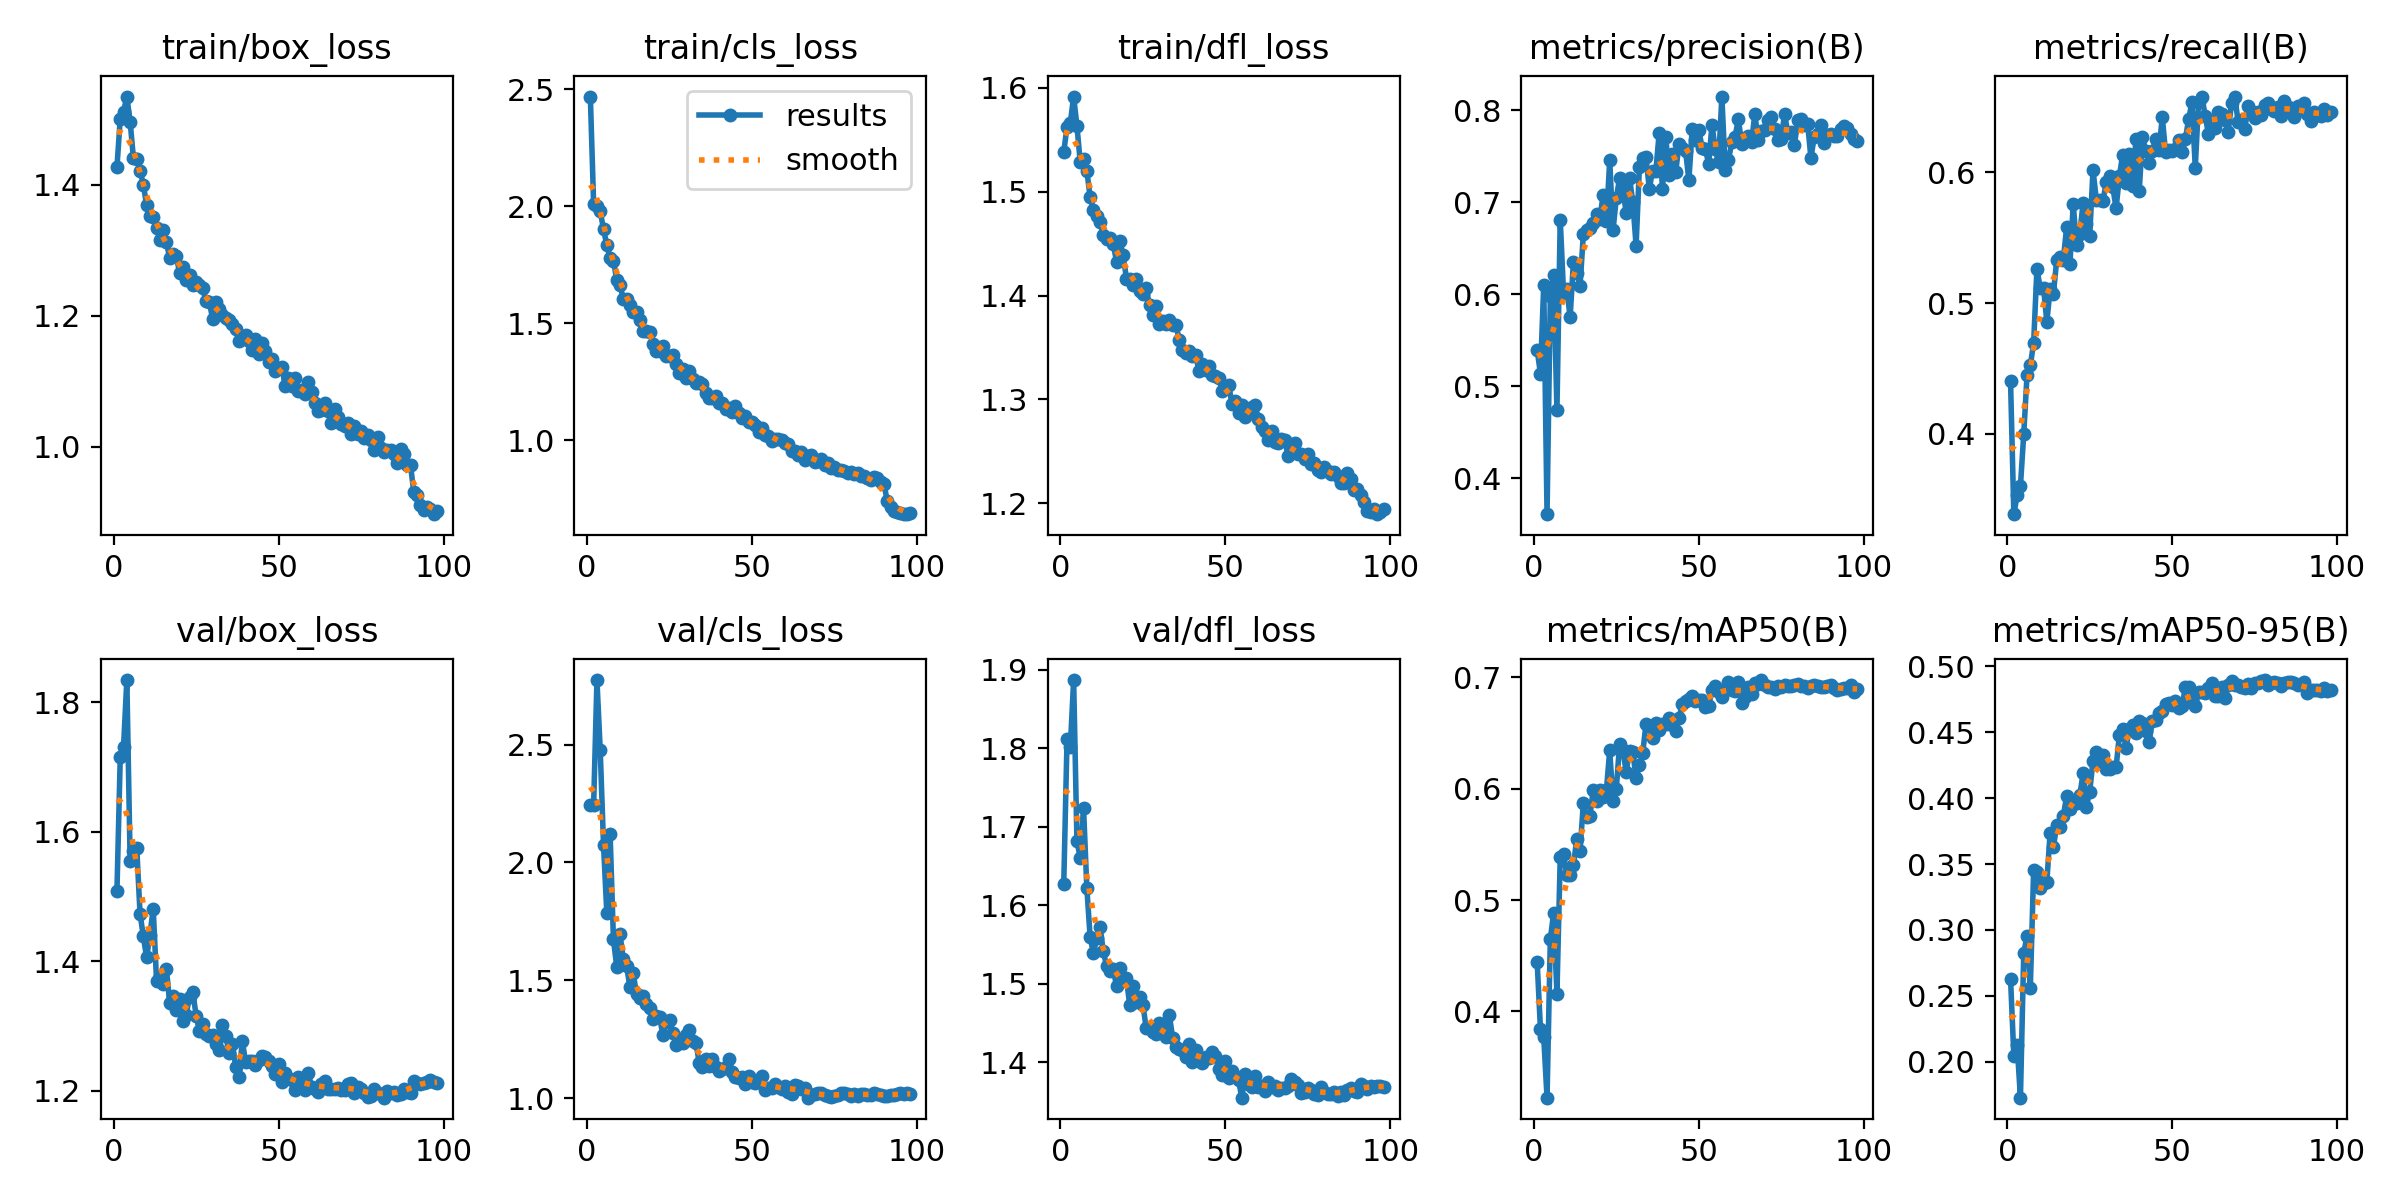

== confusion_matrix_normalized.png


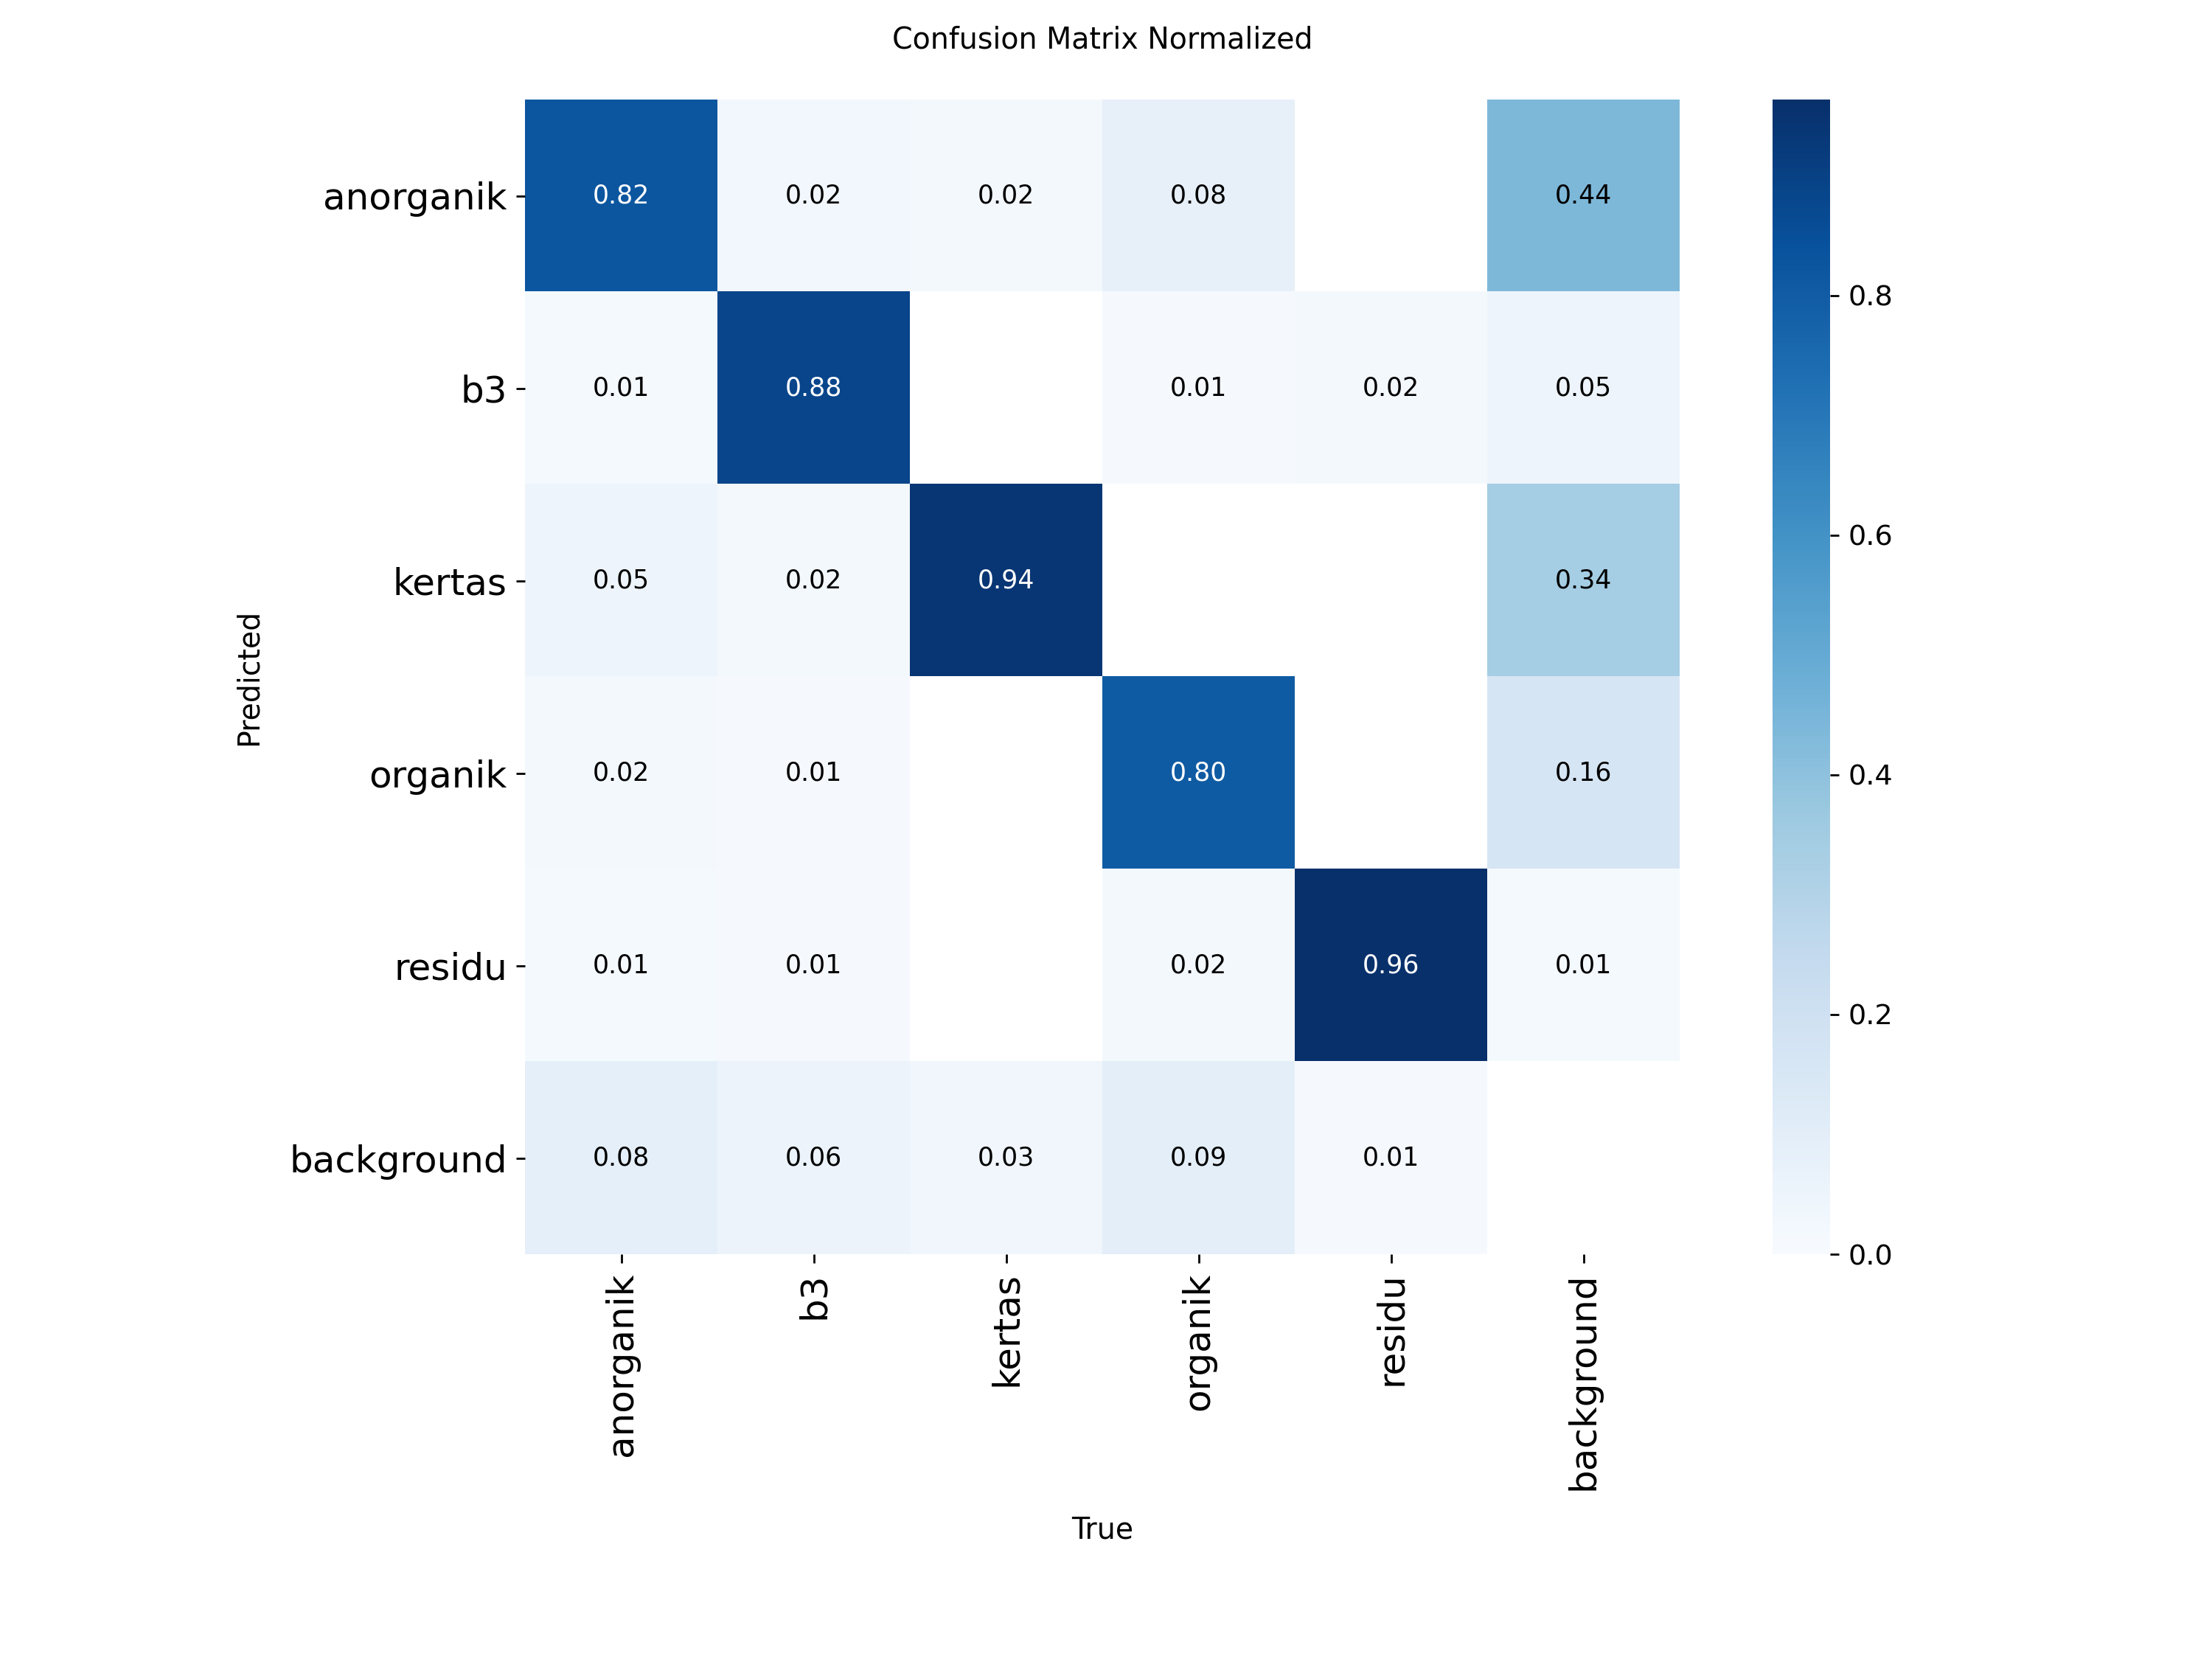

== BoxPR_curve.png


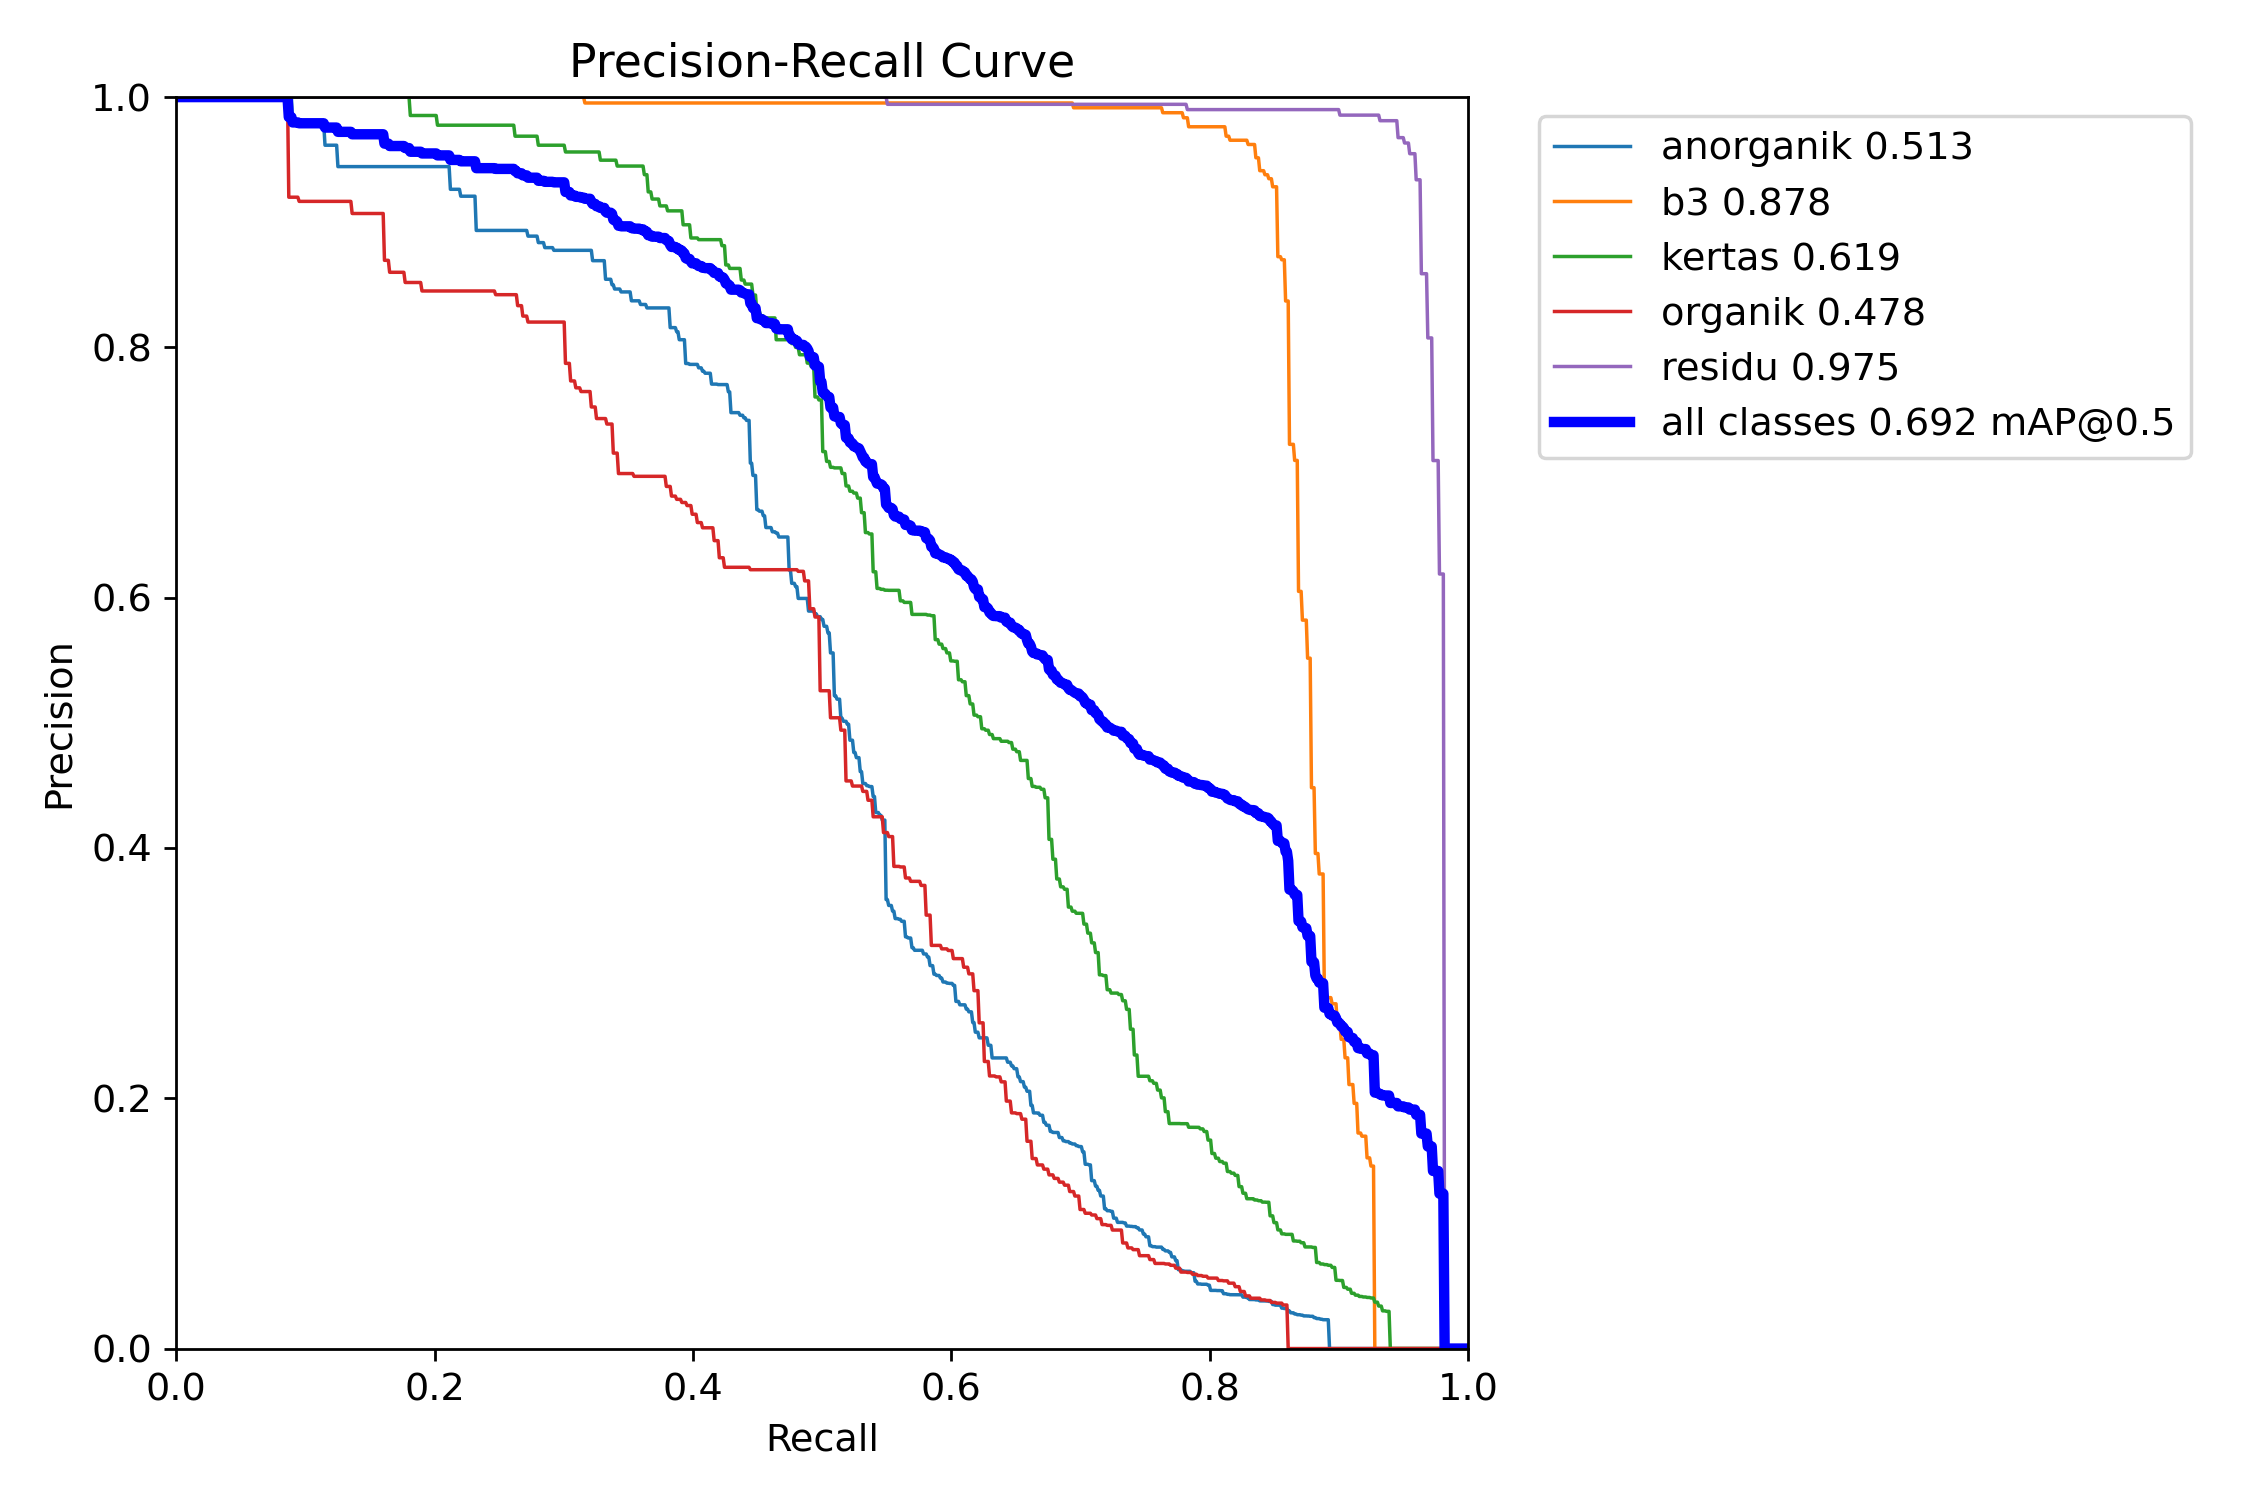

In [57]:
from IPython.display import Image, display

for f in ["results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"]:
    p = Path(results.save_dir) / f
    if p.exists():
        print("==", f)
        display(Image(filename=str(p), width=800))

## Val

In [58]:
from IPython.display import Image, display

best = YOLO(str(BEST))

val = best.val(data=DATA, split="val", imgsz=IMGSZ, conf=0.001, iou=0.6,
               project=PROJECT, name="val_eval_v2", exist_ok=True)

print(f"\nVALID  mAP50={val.box.map50:.3f} | mAP50-95={val.box.map:.3f} | "
      f"P={val.box.mp:.3f} | R={val.box.mr:.3f}")
print("\nPer kelas:")
for i, c in enumerate(val.box.ap_class_index):
    print(f"  {val.names[int(c)]:10s} AP50={val.box.ap50[i]:.3f} | AP50-95={val.box.ap[i]:.3f}")
print("Hasil tersimpan di:", val.save_dir)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1350.2±615.5 MB/s, size: 28.9 KB)
val: Scanning /content/merged_v2/valid/labels.cache... 799 images, 20 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 799/799 257.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 7.3it/s 6.8s
                   all        799       1500      0.778      0.651      0.698       0.49
             anorganik        165        401      0.757      0.429      0.525      0.283
                    b3        217        304      0.945      0.842      0.882      0.696
                kertas        170        332      0.633      0.539      0.623      0.377
               organik         64        243      0.616      0.482      0.485      0.265
                residu        167        

## Test

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1677.3±375.7 MB/s, size: 37.5 KB)
val: Scanning /content/merged_v2/test/labels... 773 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 773/773 2.1Kit/s 0.4s
val: New cache created: /content/merged_v2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 7.8it/s 6.3s
                   all        773       1411       0.78      0.683      0.736      0.507
             anorganik        164        336      0.807      0.548      0.641       0.35
                    b3        217        284      0.939       0.86      0.915      0.679
                kertas        170        316      0.631      0.541       0.59       0.37
               organik         62        256      0.593      0.496      0.543  

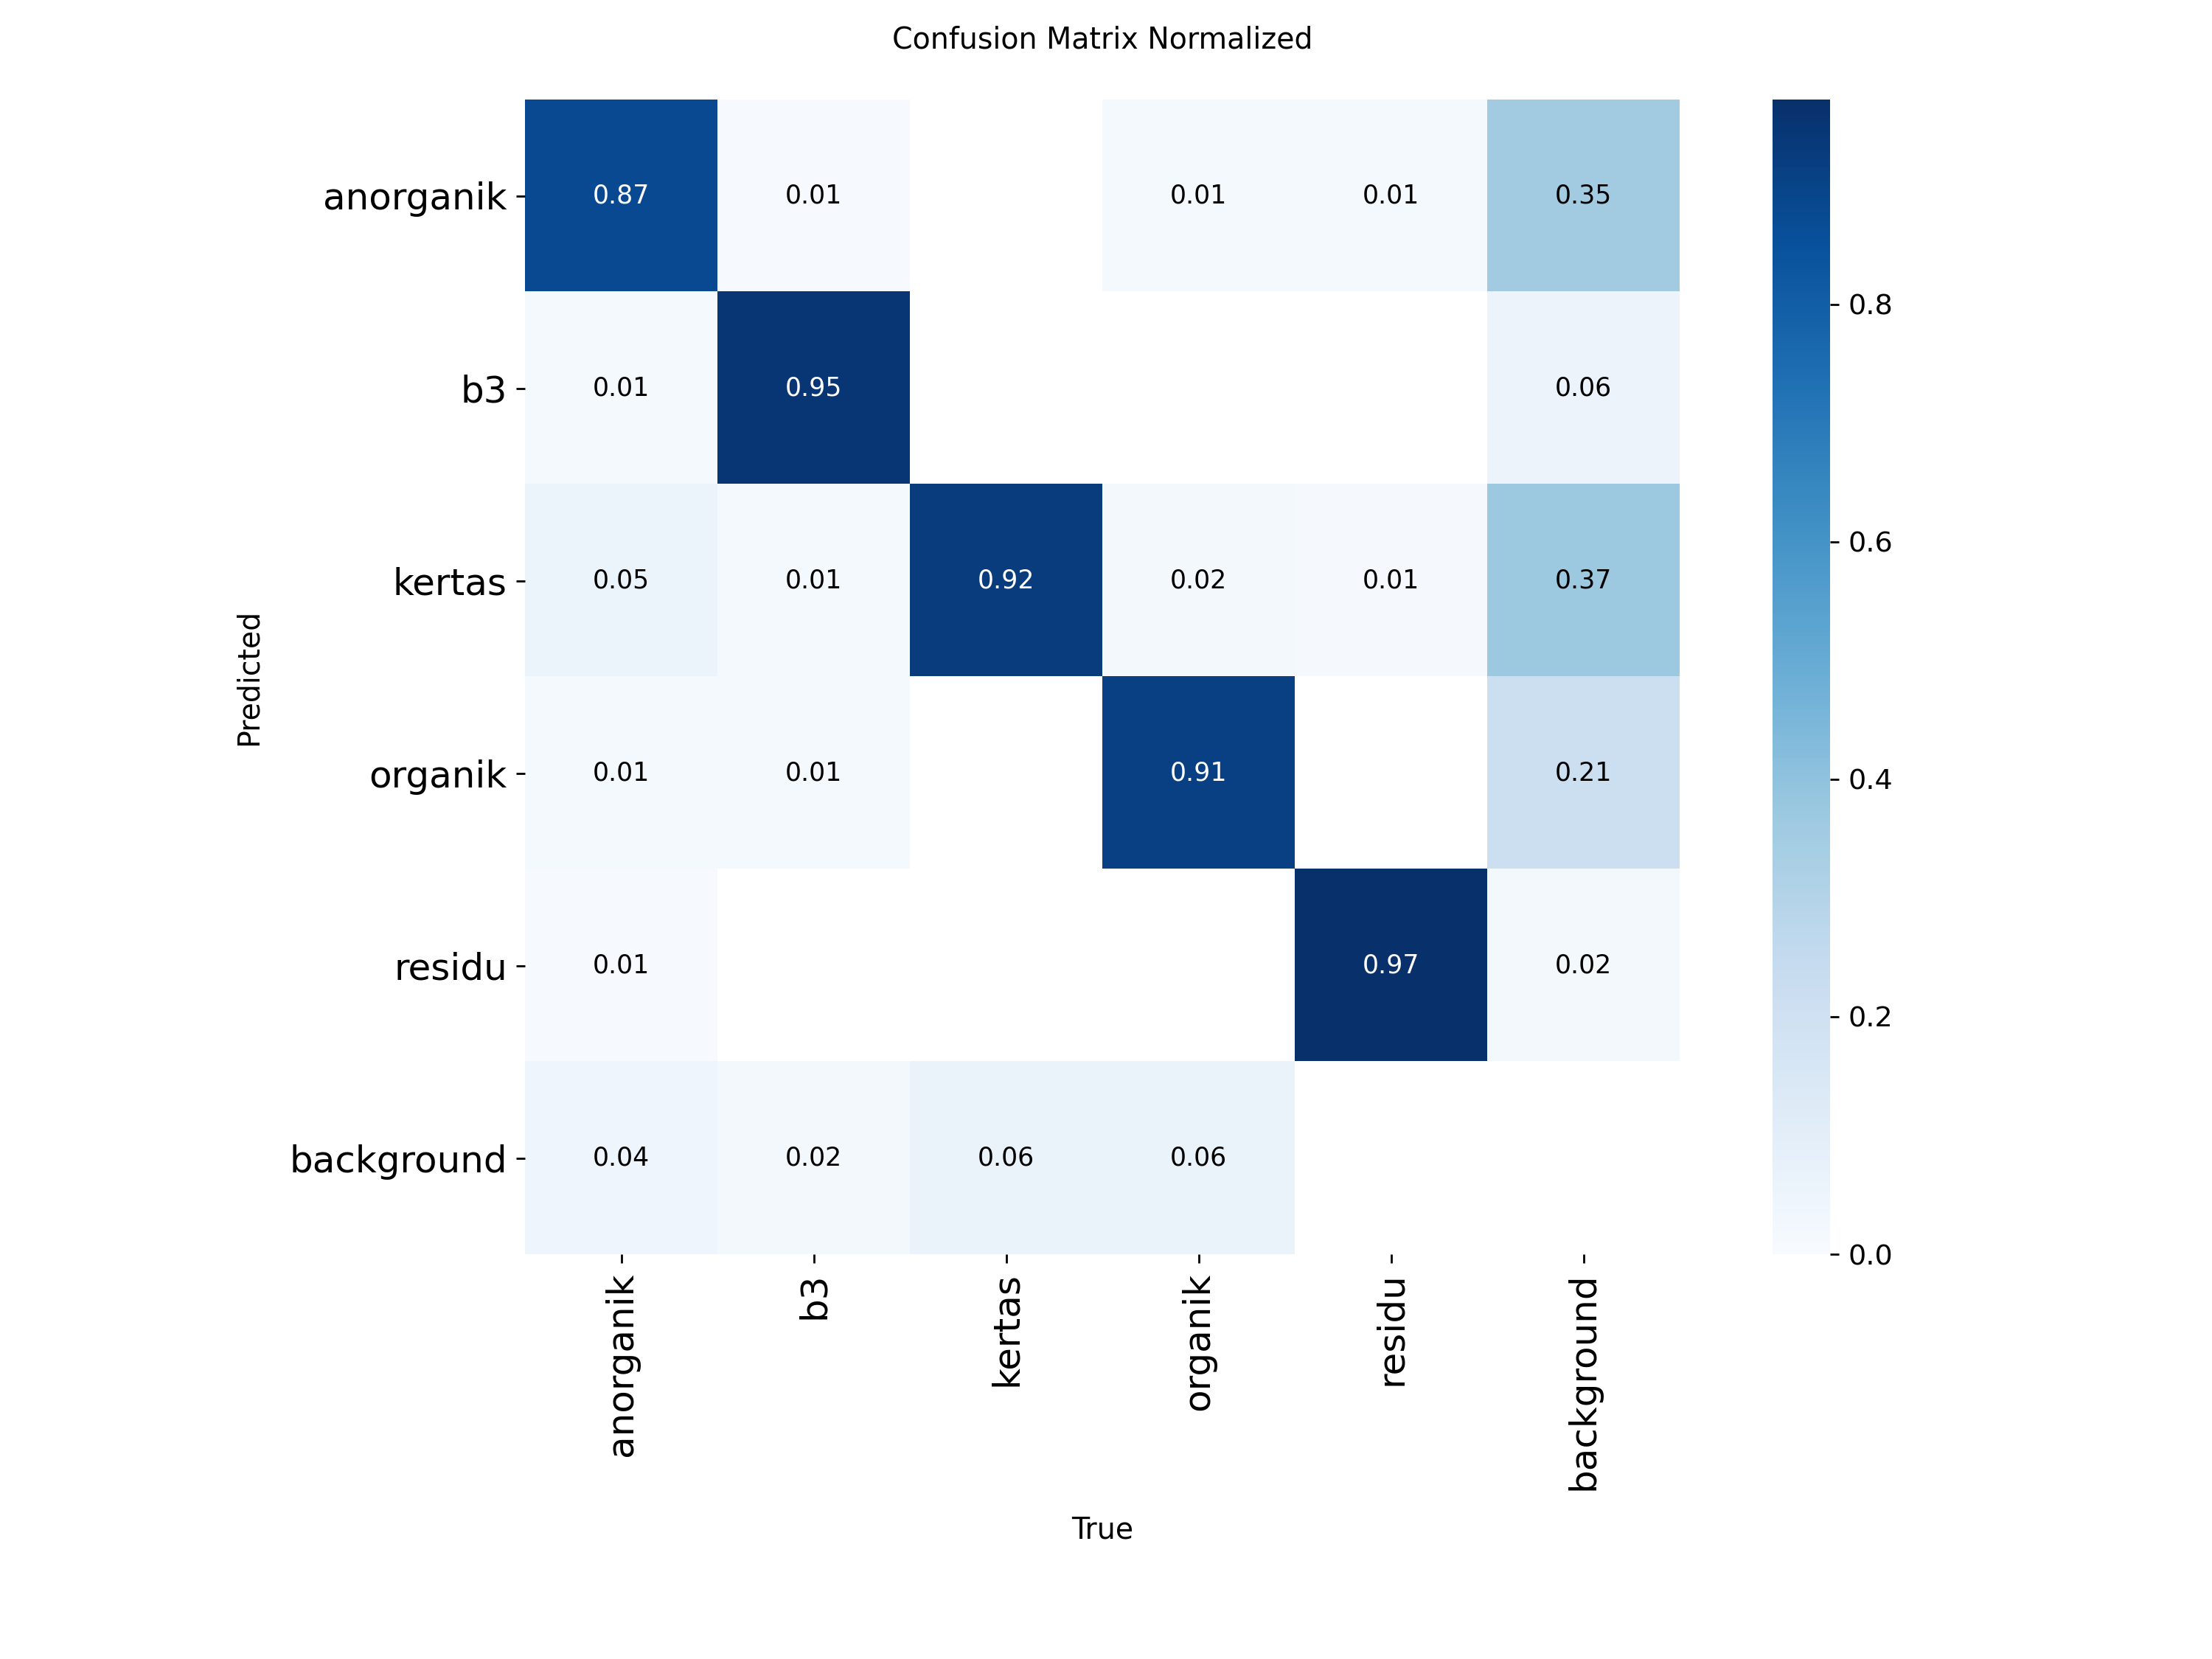

In [59]:
test = best.val(data=DATA, split="test", imgsz=IMGSZ, conf=0.001, iou=0.6,
                project=PROJECT, name="test_eval_v2", exist_ok=True)

print(f"\nTEST  mAP50={test.box.map50:.3f} | mAP50-95={test.box.map:.3f} | "
      f"P={test.box.mp:.3f} | R={test.box.mr:.3f}")
print("\nPer kelas:")
for i, c in enumerate(test.box.ap_class_index):
    print(f"  {test.names[int(c)]:10s} AP50={test.box.ap50[i]:.3f} | AP50-95={test.box.ap[i]:.3f}")
print("Hasil tersimpan di:", test.save_dir)

display(Image(filename=str(Path(test.save_dir) / "confusion_matrix_normalized.png"), width=800))

In [60]:
neg_imgs = sorted(str(p) for p in Path("negatif_test").glob("*"))
print("Jumlah negatif uji:", len(neg_imgs))

print(f"{'conf':>6} | gambar dgn false positive | total box salah")
for c in [0.25, 0.35, 0.45, 0.55, 0.65, 0.75]:
    preds = best.predict(neg_imgs, imgsz=IMGSZ, conf=c, iou=0.5, verbose=False)
    n_fp_img = sum(len(r.boxes) > 0 for r in preds)
    n_fp_box = sum(len(r.boxes) for r in preds)
    print(f"{c:6.2f} | {n_fp_img:3d}/{len(neg_imgs)} ({100*n_fp_img/len(neg_imgs):4.1f}%)        | {n_fp_box}")

Jumlah negatif uji: 30
  conf | gambar dgn false positive | total box salah
  0.25 |   5/30 (16.7%)        | 12
  0.35 |   4/30 (13.3%)        | 6
  0.45 |   4/30 (13.3%)        | 5
  0.55 |   2/30 ( 6.7%)        | 2
  0.65 |   1/30 ( 3.3%)        | 1
  0.75 |   1/30 ( 3.3%)        | 1


In [61]:
from collections import defaultdict, Counter

SRC = {f"d{i}": Path(d["path"]).name for i, d in enumerate(DATASETS)}
SRC["neg"] = "negatif"

inst = {s: defaultdict(Counter) for s in SPLITS}
imgs = {s: defaultdict(Counter) for s in SPLITS}
for s in SPLITS:
    for lbl in Path(OUT, s, "labels").glob("*.txt"):
        src = SRC.get(lbl.stem.split("_")[0], "?")
        cls = [FINAL[int(l.split()[0])] for l in lbl.read_text().splitlines() if l.strip()]
        for c in cls:
            inst[s][src][c] += 1
        for c in set(cls):
            imgs[s][src][c] += 1

for c in FINAL:
    print(f"\n== {c}")
    for s in SPLITS:
        parts = [f"{src}: {imgs[s][src][c]} gbr/{inst[s][src][c]} obj"
                 for src in imgs[s] if imgs[s][src][c]]
        print(f"  {s:5s} -> " + " | ".join(parts))


== anorganik
  train -> sampah.v6i.yolov11: 69 gbr/108 obj | sampah organik anorganik.v2-12-kelas.yolov11: 115 gbr/165 obj | kategori sampah.v1i.yolov11: 533 gbr/1307 obj | Sampah.v1i.yolov11: 34 gbr/40 obj | Paper.v1i.yolov11: 1 gbr/2 obj
  valid -> Paper.v1i.yolov11: 1 gbr/7 obj | kategori sampah.v1i.yolov11: 118 gbr/323 obj | Sampah.v1i.yolov11: 7 gbr/9 obj | sampah organik anorganik.v2-12-kelas.yolov11: 24 gbr/35 obj | sampah.v6i.yolov11: 15 gbr/27 obj
  test  -> Paper.v1i.yolov11: 1 gbr/1 obj | sampah organik anorganik.v2-12-kelas.yolov11: 25 gbr/31 obj | sampah.v6i.yolov11: 16 gbr/26 obj | kategori sampah.v1i.yolov11: 113 gbr/269 obj | Sampah.v1i.yolov11: 9 gbr/9 obj

== b3
  train -> Sortir Limbah Elektronik.v5i.yolov11: 526 gbr/697 obj | battery.v1i.yolov11: 106 gbr/282 obj | Sampah.v1i.yolov11: 35 gbr/35 obj | e-waste.v2i.yolov11: 269 gbr/276 obj | Biomedical waste segregation.v1i.yolov11: 85 gbr/94 obj
  valid -> Biomedical waste segregation.v1i.yolov11: 17 gbr/24 obj | Sort

In [62]:
import numpy as np

px = test.box.curves_results[2][0]          # sumbu confidence
P  = test.box.curves_results[2][1]          # precision vs confidence
R  = test.box.curves_results[3][1]          # recall vs confidence
names = [test.names[int(c)] for c in test.box.ap_class_index]

print(f"{'kelas':10s} | " + " | ".join(f"conf {c:.2f} (P/R)" for c in [0.25, 0.35, 0.45, 0.55, 0.65]))
for i, n in enumerate(names):
    cells = []
    for c in [0.25, 0.35, 0.45, 0.55, 0.65]:
        j = int(np.argmin(np.abs(px - c)))
        cells.append(f"{P[i][j]:.2f}/{R[i][j]:.2f}".center(14))
    print(f"{n:10s} | " + " | ".join(cells))

kelas      | conf 0.25 (P/R) | conf 0.35 (P/R) | conf 0.45 (P/R) | conf 0.55 (P/R) | conf 0.65 (P/R)
anorganik  |   0.79/0.56    |   0.85/0.52    |   0.89/0.48    |   0.89/0.43    |   0.90/0.36   
b3         |   0.93/0.86    |   0.95/0.86    |   0.96/0.84    |   0.97/0.83    |   0.97/0.81   
kertas     |   0.62/0.56    |   0.69/0.51    |   0.72/0.47    |   0.76/0.43    |   0.85/0.39   
organik    |   0.56/0.51    |   0.64/0.45    |   0.66/0.39    |   0.71/0.34    |   0.76/0.30   
residu     |   0.93/0.97    |   0.94/0.97    |   0.94/0.96    |   0.96/0.96    |   0.97/0.96   


In [63]:
preds = best.predict(neg_imgs, imgsz=IMGSZ, conf=0.25, iou=0.5, verbose=False)
rows = []
for p, r in zip(neg_imgs, preds):
    for b in r.boxes:
        rows.append((float(b.conf), FINAL[int(b.cls)], Path(p).name))

for conf, cls, name in sorted(rows, reverse=True):
    print(f"{conf:.2f}  {cls:10s} {name}")

0.77  organik    negtest_0019.jpg
0.62  residu     negtest_0029.jpg
0.54  organik    negtest_0019.jpg
0.48  organik    negtest_0007.jpg
0.47  organik    negtest_0028.jpg
0.36  kertas     negtest_0019.jpg
0.35  kertas     negtest_0019.jpg
0.34  organik    negtest_0019.jpg
0.32  organik    negtest_0007.jpg
0.32  kertas     negtest_0008.jpg
0.28  organik    negtest_0019.jpg
0.28  kertas     negtest_0019.jpg


In [64]:
import numpy as np

def best_conf_table(res, title):
    px = res.box.curves_results[1][0]
    F1 = res.box.curves_results[1][1]
    P  = res.box.curves_results[2][1]
    R  = res.box.curves_results[3][1]
    names = [res.names[int(c)] for c in res.box.ap_class_index]
    print(title)
    print(f"{'kelas':10s} | conf terbaik | F1   | P/R")
    for i, n in enumerate(names):
        j = int(np.argmax(F1[i]))
        print(f"{n:10s} | {px[j]:.2f}         | {F1[i][j]:.2f} | {P[i][j]:.2f}/{R[i][j]:.2f}")
    print()

best_conf_table(val,  "VALID (dipakai menentukan ambang)")
best_conf_table(test, "TEST (hanya untuk mengecek ambang bertahan)")

VALID (dipakai menentukan ambang)
kelas      | conf terbaik | F1   | P/R
anorganik  | 0.28         | 0.56 | 0.75/0.44
b3         | 0.39         | 0.90 | 0.97/0.84
kertas     | 0.50         | 0.61 | 0.80/0.49
organik    | 0.32         | 0.54 | 0.62/0.48
residu     | 0.66         | 0.96 | 0.98/0.95

TEST (hanya untuk mengecek ambang bertahan)
kelas      | conf terbaik | F1   | P/R
anorganik  | 0.29         | 0.66 | 0.82/0.55
b3         | 0.33         | 0.90 | 0.95/0.86
kertas     | 0.24         | 0.59 | 0.62/0.56
organik    | 0.16         | 0.54 | 0.50/0.59
residu     | 0.68         | 0.97 | 0.98/0.96



Prediksi organik per sumber:
  Biomedical waste segregation tertukar dgn b3              1
  Paper.v1i.yolov11            TANPA LABEL                  1
  Sampah.v1i.yolov11           TANPA LABEL                  11
  Sampah.v1i.yolov11           benar                        6
  kategori sampah.v1i.yolov11  TANPA LABEL                  1
  sampah organik anorganik.v2- TANPA LABEL                  43
  sampah organik anorganik.v2- benar                        87
  sampah.v6i.yolov11           TANPA LABEL                  28
  sampah.v6i.yolov11           benar                        16
  sampah.v6i.yolov11           tertukar dgn anorganik       7

Organik berlabel yang terlewat: {'Sampah.v1i.yolov11': 1, 'sampah organik anorganik.v2-': 119, 'sampah.v6i.yolov11': 16}


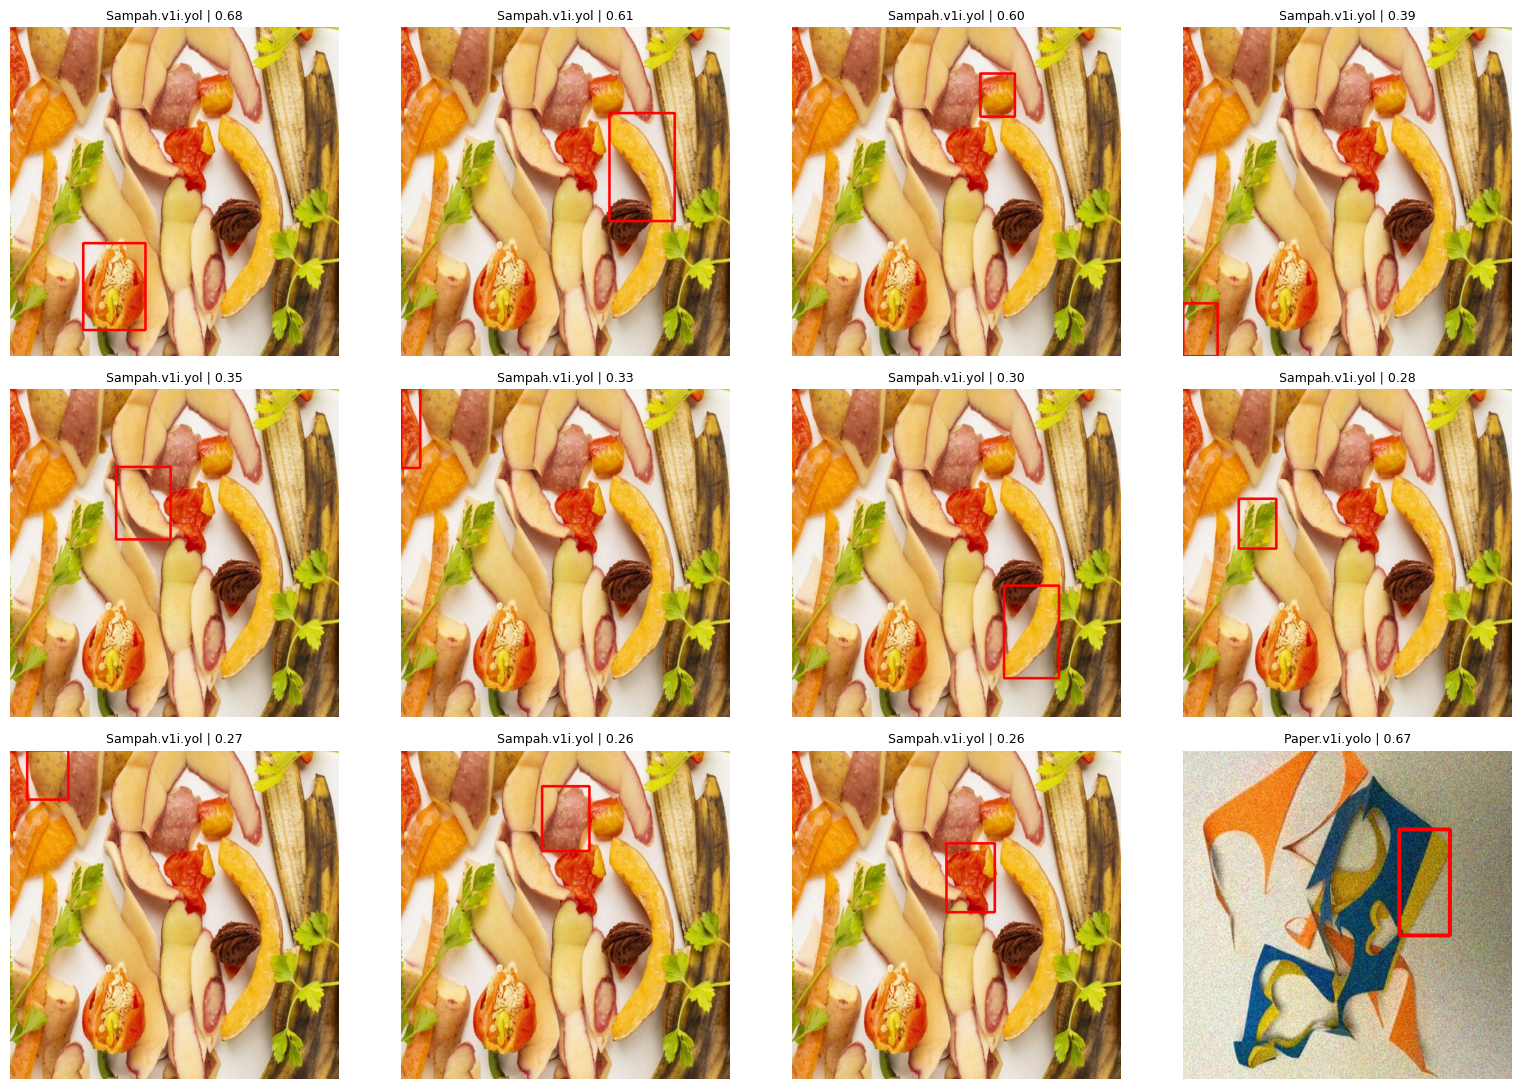

In [65]:
import cv2, matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

ORG, CONF = FINAL.index("organik"), 0.26
SRC = {f"d{i}": Path(d["path"]).name[:28] for i, d in enumerate(DATASETS)}
best = YOLO(str(BEST))

def load_gt(lbl, w, h):
    out = []
    for l in lbl.read_text().splitlines():
        p = l.split()
        if len(p) == 5:
            c = int(p[0]); x, y, bw, bh = map(float, p[1:])
            out.append((c, [(x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h]))
    return out

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

imgs = [p for p in sorted(Path(OUT, "valid", "images").glob("*"))
        if Path(OUT, "valid", "labels", p.stem + ".txt").exists() and not p.name.startswith("neg_")]
preds = best.predict([str(p) for p in imgs], imgsz=IMGSZ, conf=CONF, iou=0.6, verbose=False)

stat, missed, fp_unlabeled = Counter(), Counter(), []
for p, r in zip(imgs, preds):
    h, w = r.orig_shape
    gt = load_gt(Path(OUT, "valid", "labels", p.stem + ".txt"), w, h)
    src = SRC.get(p.name.split("_")[0], "?")
    pred_org = [b.xyxy[0].tolist() for b in r.boxes if int(b.cls) == ORG]
    for box, b in zip(pred_org, [b for b in r.boxes if int(b.cls) == ORG]):
        s, c = max(((iou(box, g[1]), g[0]) for g in gt), default=(0, None))
        if s >= 0.5 and c == ORG:   kind = "benar"
        elif s >= 0.5:              kind = f"tertukar dgn {FINAL[c]}"
        else:                       kind = "TANPA LABEL"; fp_unlabeled.append((p, box, float(b.conf)))
        stat[(src, kind)] += 1
    for c, g in gt:                  # objek organik berlabel yang tidak ditemukan
        if c == ORG and not any(iou(g, pb) >= 0.5 for pb in pred_org):
            missed[src] += 1

print("Prediksi organik per sumber:")
for (src, kind), n in sorted(stat.items()):
    print(f"  {src:28s} {kind:28s} {n}")
print("\nOrganik berlabel yang terlewat:", dict(missed))

sel = fp_unlabeled[:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax in axes.flat: ax.axis("off")
for ax, (p, box, c) in zip(axes.flat, sel):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), 3)
    ax.imshow(im); ax.set_title(f"{SRC.get(p.name.split('_')[0],'?')[:14]} | {c:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

In [66]:
from pathlib import Path
from google.colab import files

print(BEST, "| ada:", BEST.exists(), "| ukuran: %.1f MB" % (BEST.stat().st_size / 1e6))

import shutil
shutil.copy(BEST, "sampah_best.pt")
files.download("sampah_best.pt")

/content/runs/detect/runs/sampah_yolo11n_v2/weights/best.pt | ada: True | ukuran: 5.5 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Convert -> ONNX


In [67]:
import numpy as np

test_imgs = sorted(str(p) for p in Path(OUT, "test", "images").glob("*"))
preds = best.predict(test_imgs, imgsz=IMGSZ, conf=0.25, iou=0.5, verbose=False)

scores = {n: [] for n in FINAL}
for r in preds:
    for b in r.boxes:
        scores[FINAL[int(b.cls)]].append(float(b.conf))

print(f"{'kelas':10s} | jumlah | median | persentil 25")
for n, s in scores.items():
    if s:
        print(f"{n:10s} | {len(s):6d} | {np.median(s):.2f}   | {np.percentile(s,25):.2f}")

kelas      | jumlah | median | persentil 25
anorganik  |    220 | 0.67   | 0.46
b3         |    262 | 0.87   | 0.82
kertas     |    268 | 0.68   | 0.43
organik    |    204 | 0.58   | 0.38
residu     |    225 | 0.88   | 0.84


In [68]:
onnx_path = best.export(
    format="onnx",
    imgsz=IMGSZ,
    opset=12,        # kompatibel luas dengan ONNX Runtime Web
    simplify=True,
    dynamic=False,   # ukuran input tetap, lebih stabil di browser
    half=False,
    nms=False,       # NMS dikerjakan di JavaScript (iou_nms dari config.json)
)
print("ONNX:", onnx_path)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ This model has no one-to-one head; using one-to-many outputs.
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 2.7 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/sampah_yolo11n_v2/weights/best.pt' with input shape (1, 3, 416, 416) BCHW and output shape(s) (1, 9, 3549) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.4s, saved as '/content/runs/detect/runs/sampah_yolo11n_v2/weights/best.onnx' (10.1 MB)

Export complete (2.7s)
Results saved to /content/runs/detect/runs/sampah_yolo11n_v2/weights/best.onnx
Predict:         yolo predict task=detect model=/con

In [69]:
import onnxruntime as ort, numpy as np

sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
inp, out = sess.get_inputs()[0], sess.get_outputs()[0]
print("Input :", inp.name, inp.shape)    # [1, 3, 416, 416]
print("Output:", out.name, out.shape)    # [1, 9, N] = 4 koordinat + 5 kelas

dummy = np.random.rand(1, 3, IMGSZ, IMGSZ).astype(np.float32)
print("Hasil dummy:", sess.run(None, {inp.name: dummy})[0].shape)
print("Urutan kelas untuk aplikasi web:", FINAL)
print("Ukuran file: %.1f MB" % (Path(onnx_path).stat().st_size / 1e6))

Input : images [1, 3, 416, 416]
Output: output0 [1, 9, 3549]
Hasil dummy: (1, 9, 3549)
Urutan kelas untuk aplikasi web: ['anorganik', 'b3', 'kertas', 'organik', 'residu']
Ukuran file: 10.6 MB


## Download Model

In [70]:
from google.colab import files
import shutil

shutil.copy(onnx_path, "sampah_yolo11n.onnx")
files.download("sampah_yolo11n.onnx")   # dipakai di web app

files.download(str(BEST))               # cadangan .pt untuk retraining/evaluasi lanjutan

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>